# `scripts/calibration.py`

報告 `report/expected_score.typ` 的「斜率 β 與累計局數」：依累計局數分層的校準斜率（`calibration_cox`）。

本 notebook 由 `notebooks/build.py` 從腳本自動產生，內容以腳本為準。

期望得分的校準：Elo 形式的 E 是否校準，和局機率與白方優勢是否隨等級變化。
樣本為 2014 年 Bullet、Blitz、Classical 的對局；2013 年起的對局只用來算累計局數。

In [1]:
import os
import sys

In [2]:
os.environ["JAX_PLATFORMS"] = "cpu"
sys.path.insert(0, "scripts")

In [3]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy import optimize

In [4]:
import likelihood as lk
import novice
import ordinal

In [5]:
jax.config.update("jax_enable_x64", True)

In [6]:
UTC = "UTC"
CLASSES = ["Bullet", "Blitz", "Classical"]
# 累計局數的門檻是暫定的新手期界線；calibration_experience.png 用來檢查這條界線是否落在校準斜率趨穩之後
N_EST = novice.GAMES
ELO = ordinal.Q
# 有序模型與 proportional odds 檢驗在每個速度類別抽 N_FIT 局的簡單隨機樣本上估計
N_FIT = 1_000_000

只讀需要的欄位。2014 年 12 月以前的無鐘對局計入
Classical 的等級分，但沒有時限，與有鐘的對局不是同一種對局，與通信棋一同排除

In [7]:
g = (
    pl.scan_parquet("data/processed/lichess_games.parquet")
    .filter(pl.col("speed") != "Correspondence", pl.col("base_seconds").is_not_null(), pl.col("start") < pl.datetime(2015, 1, 1, time_zone=UTC))
    .select(
        "start", "speed", "white_elo", "black_elo",
        arena=pl.col("tournament_id").is_not_null(),
        y=pl.col("result").replace_strict({"0-1": 0, "1/2-1/2": 1, "1-0": 2}, default=None, return_dtype=pl.Int8),
        w=pl.col("white_id"),
        b=pl.col("black_id"),
    )
    .with_row_index("i")
    .collect(engine="streaming")
)
# 帳號代碼在子樣本中不連續，壓成連續代碼，後面 bincount 以代碼為群
code = pl.concat([g["w"], g["b"]]).rank("dense").cast(pl.UInt32) - 1
g = g.with_columns(w=code[: g.height], b=code[g.height :])
del code
# 資料從 2013-01 開始，此月就出現的帳號此前可能已有對局，累計局數低估
censored = (
    pl.concat([g.select("start", p="w"), g.select("start", p="b")])
    .group_by("p")
    .agg(pl.col("start").min())
    .filter(pl.col("start") < pl.datetime(2013, 2, 1, time_zone=UTC))
    .select("p", c=pl.lit(True))
)
# 累計局數含 "*" 與缺等級分的對局，因為它們同樣是玩家的經驗；依速度類別分開算以壓低峰值記憶體
nprev = pl.concat([
    pl.concat([g.filter(pl.col("speed") == tc).select("i", "start", p="w"), g.filter(pl.col("speed") == tc).select("i", "start", p="b")])
    .sort("i")
    .with_columns(n_prev=pl.int_range(pl.len(), dtype=pl.UInt32).over("p"))
    .filter(pl.col("start") >= pl.datetime(2014, 1, 1, time_zone=UTC))
    .select("i", "p", "n_prev")
    for tc in CLASSES
])
d = (
    g.lazy()
    .filter(
        pl.col("start") >= pl.datetime(2014, 1, 1, time_zone=UTC),
        pl.col("y").is_not_null(),
        pl.col("white_elo").is_not_null(),
        pl.col("black_elo").is_not_null(),
    )
    .join(nprev.lazy().rename({"p": "w", "n_prev": "nw"}), on=["i", "w"])
    .join(nprev.lazy().rename({"p": "b", "n_prev": "nb"}), on=["i", "b"])
    .join(censored.lazy().rename({"p": "w", "c": "cw"}), on="w", how="left")
    .join(censored.lazy().rename({"p": "b", "c": "cb"}), on="b", how="left")
    .sort("i")
    .with_columns(
        diff=(pl.col("white_elo") - pl.col("black_elo")).cast(pl.Float64),
        rbar=(pl.col("white_elo") + pl.col("black_elo")) / 2,
        n_min=pl.min_horizontal("nw", "nb"),
        source=pl.when(pl.col("arena")).then(pl.lit("arena")).otherwise(pl.lit("lobby")),
        period=pl.when(pl.col("start") < pl.datetime(2014, 8, 1, time_zone=UTC)).then(pl.lit("Jan-Jul")).otherwise(pl.lit("Aug-Dec")),
        train=pl.col("start") < pl.datetime(2014, 7, 1, time_zone=UTC),
        censored=pl.col("cw").fill_null(False) | pl.col("cb").fill_null(False),
    )
    .with_columns(
        score=pl.col("y") / 2,
        E=1 / (1 + 10 ** (-pl.col("diff") / 400)),
        xr=(pl.col("rbar") - 1500) / 100,
        xd=pl.col("diff") / 100,
        est=pl.col("n_min") >= N_EST,
        band=pl.col("rbar").cut([1200, 1400, 1600, 1800, 2000], labels=["<1200", "1200-1400", "1400-1600", "1600-1800", "1800-2000", ">=2000"]).cast(pl.String),
        exp_bin=pl.col("n_min").cut([0, 2, 5, 10, 20, 50, 100, 200], labels=["0", "1-2", "3-5", "6-10", "11-20", "21-50", "51-100", "101-200", ">200"], left_closed=False).cast(pl.String),
        exp_group=pl.when(pl.col("n_min") < 10).then(pl.lit("<10")).when(pl.col("n_min") < N_EST).then(pl.lit(f"10-{N_EST - 1}")).otherwise(pl.lit(f">={N_EST}")),
    )
    # 字串欄在千萬列上很佔記憶體，分組標籤一律存成 Categorical
    .with_columns(pl.col("speed", "source", "period", "band", "exp_bin", "exp_group").cast(pl.Categorical))
    .select("speed", "w", "b", "y", "score", "diff", "E", "xr", "xd", "rbar", "n_min", "est", "censored", "source", "period", "train", "band", "exp_bin", "exp_group")
    .collect(engine="streaming")
)
del g, nprev, censored

In [8]:
sample = d.group_by("speed", "source", "est", "censored").agg(n=pl.len(), draw_rate=(pl.col("y") == 1).mean()).sort(pl.all())
sample.write_csv("outputs/tables/calibration_sample.csv")
print(sample)
print(d.group_by("speed").agg(n=pl.len(), est=pl.col("est").mean(), censored=pl.col("censored").mean(), censored_novice=(pl.col("censored") & ~pl.col("est")).mean()))

shape: (24, 6)
┌───────────┬────────┬───────┬──────────┬─────────┬───────────┐
│ speed     ┆ source ┆ est   ┆ censored ┆ n       ┆ draw_rate │
│ ---       ┆ ---    ┆ ---   ┆ ---      ┆ ---     ┆ ---       │
│ cat       ┆ cat    ┆ bool  ┆ bool     ┆ u32     ┆ f64       │
╞═══════════╪════════╪═══════╪══════════╪═════════╪═══════════╡
│ Blitz     ┆ arena  ┆ false ┆ false    ┆ 116710  ┆ 0.026202  │
│ Blitz     ┆ arena  ┆ false ┆ true     ┆ 6469    ┆ 0.031535  │
│ Blitz     ┆ arena  ┆ true  ┆ false    ┆ 392558  ┆ 0.035062  │
│ Blitz     ┆ arena  ┆ true  ┆ true     ┆ 38281   ┆ 0.041796  │
│ Blitz     ┆ lobby  ┆ false ┆ false    ┆ 787422  ┆ 0.034167  │
│ …         ┆ …      ┆ …     ┆ …        ┆ …       ┆ …         │
│ Classical ┆ arena  ┆ true  ┆ true     ┆ 2025    ┆ 0.077037  │
│ Classical ┆ lobby  ┆ false ┆ false    ┆ 863900  ┆ 0.036981  │
│ Classical ┆ lobby  ┆ false ┆ true     ┆ 36004   ┆ 0.036635  │
│ Classical ┆ lobby  ┆ true  ┆ false    ┆ 2062173 ┆ 0.040477  │
│ Classical ┆ lobby  ┆ tr

校準曲線：依 E 分組的平均得分減平均 E，分層看

In [9]:
strata = {"all": pl.lit("all"), "source": pl.col("source"), "band": pl.col("band"), "experience": pl.col("exp_group"), "period": pl.col("period")}
curve = pl.concat([
    d.filter(pl.col("est") | pl.lit(k == "experience"))
    .with_columns(stratum=v.cast(pl.String), e_bin=(pl.col("E") * 20).floor().clip(0, 19) / 20 + 0.025)
    .group_by("speed", "stratum", "e_bin")
    .agg(
        n=pl.len(),
        e_mean=pl.col("E").mean(),
        score_mean=pl.col("score").mean(),
        resid_mean=(pl.col("score") - pl.col("E")).mean(),
        resid_se=(pl.col("score") - pl.col("E")).std() / pl.len().sqrt(),
        p_win=(pl.col("y") == 2).mean(),
        p_draw=(pl.col("y") == 1).mean(),
        p_loss=(pl.col("y") == 0).mean(),
    )
    .with_columns(stratum_type=pl.lit(k))
    for k, v in strata.items()
]).sort("stratum_type", "speed", "stratum", "e_bin")
curve.write_csv("outputs/tables/calibration_curve.csv")

勢均力敵的對局（|d| <= 25）看和局率與白方得分隨平均等級分的變化，不經模型

In [10]:
level = (
    d.filter(pl.col("est"), pl.col("diff").abs() <= 25)
    .with_columns(r_bin=(pl.col("rbar") / 100).floor() * 100 + 50)
    .group_by("speed", "r_bin")
    .agg(n=pl.len(), draw_rate=(pl.col("y") == 1).mean(), white_score=pl.col("score").mean(), e_mean=pl.col("E").mean())
    .filter(pl.col("n") >= 500)
    .sort("speed", "r_bin")
)
level.write_csv("outputs/tables/calibration_level.csv")

有序模型：白方的潛在優勢 eta 隨分差與平均等級分變化，和局帶寬 w 隨平均等級分變化。
P(勝) = F(eta - w)、P(不輸) = F(eta + w)。w 的等級分項讓兩個門檻各自移動，
所以「和局率是否隨等級變化」與「白方優勢是否隨等級變化」可分開檢驗

In [11]:
def ll_ord(t, xr, xd, y):
    eta = t[0] + t[1] * xr + t[2] * xr**2 + (t[3] + t[4] * xr) * xd
    return ordinal.ll(eta, jnp.exp(t[5] + t[6] * xr + t[7] * xr**2), y)

平均得分的 quasi-likelihood（fractional logit）：只對得分的平均建模，和局的 0.5 照實際值代入，
不把結果當二元。logit(E) = d ln10/400，故截距 0、斜率 1 即 E 校準

In [12]:
def ll_frac(t, xr, L, s):
    z = t[0] + t[1] * xr + (t[2] + t[3] * xr) * L
    return s * jax.nn.log_sigmoid(z) + (1 - s) * jax.nn.log_sigmoid(-z)

proportional odds 的對立模型：勝的門檻上，分差與分差乘等級分的斜率另有位移 t8、t9

In [13]:
def ll_ppo(t, xr, xd, y):
    eta = t[0] + t[1] * xr + t[2] * xr**2 + (t[3] + t[4] * xr) * xd
    return ordinal.ll(eta, jnp.exp(t[5] + t[6] * xr + t[7] * xr**2), y, shift=(t[8] + t[9] * xr) * xd)

In [14]:
ORD = ["white_adv", "white_adv_x_rating", "white_adv_x_rating2", "slope_diff", "slope_diff_x_rating", "log_draw_width", "log_draw_width_x_rating", "log_draw_width_x_rating2"]
T0 = [0.1, 0, 0, 0.6, 0, -2.5, 0, 0]
IDX = np.arange(8)

In [15]:
coef_rows, test_rows, implied_rows, cox_rows, pred_rows = [], [], [], [], []
fits = {}
for tc in CLASSES:
    m = d.filter(pl.col("speed") == tc, pl.col("est")).sample(N_FIT, seed=1)
    w, b = m["w"].to_numpy(), m["b"].to_numpy()
    xr, xd, y = (m[c].to_numpy().astype(np.float64) for c in ["xr", "xd", "y"])
    th, ll1, V, Hi, S, H = lk.fit(ll_ord, T0, IDX, (xr, xd, y), w, b)
    fits[tc] = th
    for k in range(8):
        coef_rows.append({"speed": tc, "model": "ordinal", "param": ORD[k], "est": th[k], "se_dyadic": np.sqrt(V[k, k]), "se_iid": np.sqrt(Hi[k, k])})

    # 各受限模型：(名稱, 固定的參數, 固定值)。naive_elo_slope 把累積 logit 的斜率固定為 ln10/400，
    # 但有和局時，與 Elo 期望得分斜率相符的累積 logit 斜率大於 ln10/400，此檢定只作對照
    for name, idx, val in [
        ("white_adv_constant_in_rating", [1, 2], [0, 0]),
        ("draw_width_constant_in_rating", [6, 7], [0, 0]),
        ("slope_constant_in_rating", [4], [0]),
        ("all_rating_terms_zero", [1, 2, 4, 6, 7], [0, 0, 0, 0, 0]),
        ("naive_elo_slope", [3], [100 * ELO]),
    ]:
        t0 = np.array(T0, dtype=float)
        t0[idx] = val
        _, ll0, *_ = lk.fit(ll_ord, t0, np.setdiff1d(IDX, idx), (xr, xd, y), w, b)
        ws, _, wp = lk.wald(th, V, np.eye(8)[idx], np.array(val, dtype=float))
        test_rows.append({"speed": tc, "model": "ordinal", "test": name, **lk.adjusted_lrt(2 * (ll1 - ll0), lk.lr_weights(Hi, V, idx)), "wald_dyadic": ws, "p_wald_dyadic": wp})

    # proportional odds：對立模型讓勝的門檻上的分差斜率另有位移，概似比檢定位移為 0
    tp, llp, Vp, Hip, *_ = lk.fit(ll_ppo, T0 + [0, 0], np.arange(10), (xr, xd, y), w, b)
    ws, _, wp = lk.wald(tp, Vp, np.eye(10)[[8, 9]], np.zeros(2))
    test_rows.append({"speed": tc, "model": "partial_po", "test": "proportional_odds_in_diff", **lk.adjusted_lrt(2 * (llp - ll1), lk.lr_weights(Hip, Vp, [8, 9])), "wald_dyadic": ws, "p_wald_dyadic": wp})
    for k, nm in enumerate(["slope_diff_shift_win", "slope_diff_x_rating_shift_win"]):
        coef_rows.append({"speed": tc, "model": "partial_po", "param": nm, "est": tp[8 + k], "se_dyadic": np.sqrt(Vp[8 + k, 8 + k]), "se_iid": np.sqrt(Hip[8 + k, 8 + k])})

    # 得分平均的校準（Cox 校準截距與斜率），E 是否在平均上校準；參數少，用該類別全部的老手對局
    mf = d.filter(pl.col("speed") == tc, pl.col("est"))
    L = np.log(mf["E"].to_numpy() / (1 - mf["E"].to_numpy()))
    af = (mf["xr"].to_numpy(), L, mf["score"].to_numpy())
    wf, bf = mf["w"].to_numpy(), mf["b"].to_numpy()
    tf, llf, Vf, Hf, *_ = lk.fit(ll_frac, [0, 0, 1, 0], np.arange(4), af, wf, bf)
    for k, nm in enumerate(["intercept", "intercept_x_rating", "slope_logitE", "slope_logitE_x_rating"]):
        coef_rows.append({"speed": tc, "model": "frac_logit", "param": nm, "est": tf[k], "se_dyadic": np.sqrt(Vf[k, k]), "se_iid": np.sqrt(Hf[k, k])})
    for name, idx, val in [
        ("elo_mean_calibrated", [0, 1, 2, 3], [0, 0, 1, 0]),
        ("no_white_adv_in_mean", [0, 1], [0, 0]),
        ("elo_slope_in_mean", [2, 3], [1, 0]),
    ]:
        t0f = np.array([0, 0, 1, 0], dtype=float)
        t0f[idx] = val
        _, ll0f, *_ = lk.fit(ll_frac, t0f, np.setdiff1d(np.arange(4), idx), af, wf, bf)
        ws, _, wp = lk.wald(tf, Vf, np.eye(4)[idx], np.array(val, dtype=float))
        test_rows.append({"speed": tc, "model": "frac_logit", "test": name, **lk.adjusted_lrt(2 * (llf - ll0f), lk.lr_weights(Hf, Vf, idx)), "wald_dyadic": ws, "p_wald_dyadic": wp})
    del mf, af

    # 模型隱含的量，在分差 0 處隨平均等級分的變化
    for r in np.arange(1000, 2301, 50):
        z = (r - 1500) / 100
        eta = th[0] + th[1] * z + th[2] * z**2
        slope = th[3] + th[4] * z
        pw, pn = ordinal.cum(eta, np.exp(th[5] + th[6] * z + th[7] * z**2))
        dS = 0.5 * slope / 100 * (pn * (1 - pn) + pw * (1 - pw))
        implied_rows.append({
            "speed": tc, "rbar": r,
            "p_draw_d0": pn - pw,
            "white_score_d0": 0.5 * (pn + pw),
            "white_adv_rating_points": 100 * eta / slope,
            "score_slope_ratio_to_elo": dS / (ELO / 4),
        })

    # 分層的 Cox 校準：只估截距與斜率，看哪些子樣本偏離 E
    mt = d.filter(pl.col("speed") == tc)
    for k, col in [("experience", "exp_bin"), ("source", "source"), ("band", "band"), ("period", "period"), ("censored", "censored")]:
        for v in mt[col].unique().sort().to_list():
            ms = mt.filter(pl.col(col) == v, pl.col("est") | pl.lit(k == "experience"))
            if ms.height < 2000:
                continue
            Ls = np.log(ms["E"].to_numpy() / (1 - ms["E"].to_numpy()))
            Ss = ms["score"].to_numpy()
            tc_, _, Vc, Hic, *_ = lk.fit(ll_frac, [0, 0, 1, 0], np.array([0, 2]), (np.zeros(ms.height), Ls, Ss), ms["w"].to_numpy(), ms["b"].to_numpy())
            # 區間與老手對局的 alpha、beta 同為反轉 score test
            lo, hi = lk.frac_score_ci(Ls, Ss, 1, tc_[[0, 2]], np.sqrt(Hic[1, 1]))
            cox_rows.append({"speed": tc, "stratum_type": k, "stratum": str(v), "n": ms.height, "intercept": tc_[0], "intercept_se": np.sqrt(Vc[0, 0]), "slope": tc_[2], "slope_se": np.sqrt(Vc[1, 1]), "slope_se_iid": np.sqrt(Hic[1, 1]), "slope_lo": lo, "slope_hi": hi})

    # 時間切分的預測評估：1-6 月估計，7-12 月評估
    tr = d.filter(pl.col("speed") == tc, pl.col("est"), pl.col("train")).sample(N_FIT, seed=2)
    te = d.filter(pl.col("speed") == tc, ~pl.col("train"))
    a = [tr[c].to_numpy().astype(np.float64) for c in ["xr", "xd", "y"]]
    th_tr, *_ = lk.fit(ll_ord, T0, IDX, a, tr["w"].to_numpy(), tr["b"].to_numpy())
    t0 = np.array(T0, dtype=float)
    th_base, *_ = lk.fit(ll_ord, t0, np.array([0, 3, 5]), a, tr["w"].to_numpy(), tr["b"].to_numpy())
    # Elo 形式的三類機率：P(和) = nu * 4E(1-E)，勝負各減去一半，得分的期望恰為 E；nu 由訓練期估計
    Etr, ytr = tr["E"].to_numpy(), tr["y"].to_numpy()
    q = 4 * Etr * (1 - Etr)
    nu = optimize.minimize_scalar(
        lambda v: -np.sum(np.where(ytr == 1, np.log(v * q), np.where(ytr == 2, np.log(Etr - v * q / 2), np.log(1 - Etr - v * q / 2)))),
        bounds=(1e-6, 0.45), method="bounded",
    ).x
    Ete, yte = te["E"].to_numpy(), te["y"].to_numpy()
    xr_te, xd_te = te["xr"].to_numpy(), te["xd"].to_numpy()
    probs = {}
    pd_ = nu * 4 * Ete * (1 - Ete)
    probs["elo_draw_split"] = np.stack([1 - Ete - pd_ / 2, pd_, Ete - pd_ / 2], 1)
    for nm, t in [("ordinal_rating", th_tr), ("ordinal_constant", th_base)]:
        eta = t[0] + t[1] * xr_te + t[2] * xr_te**2 + (t[3] + t[4] * xr_te) * xd_te
        probs[nm] = ordinal.probs(eta, np.exp(t[5] + t[6] * xr_te + t[7] * xr_te**2))
    O = np.eye(3)[yte]
    loss = {}
    for nm, p in probs.items():
        C, Co = np.cumsum(p, 1)[:, :2], np.cumsum(O, 1)[:, :2]
        loss[nm] = {
            "log_loss": -np.log(p[np.arange(len(yte)), yte]),
            "rps": ((C - Co) ** 2).sum(1) / 2,
            "score_sq_err": (p[:, 2] + p[:, 1] / 2 - yte / 2) ** 2,
        }
    for grp in ["all", "<10", f"10-{N_EST - 1}", f">={N_EST}"]:
        msk = np.ones(len(yte), bool) if grp == "all" else (te["exp_group"] == grp).to_numpy()
        wg, bg = te["w"].to_numpy()[msk], te["b"].to_numpy()[msk]
        for nm in probs:
            for metric in ["log_loss", "rps", "score_sq_err"]:
                x = loss[nm][metric][msk]
                dlt = x - loss["elo_draw_split"][metric][msk]
                se = lk.dyad_se((dlt - dlt.mean()) / len(dlt), wg, bg)
                pred_rows.append({"speed": tc, "exp_group": grp, "model": nm, "metric": metric, "n": int(msk.sum()), "mean": x.mean(), "diff_vs_elo": dlt.mean(), "diff_se_dyadic": se, "nu_train": nu})
    print(tc, "done")

Bullet done


Blitz done


Classical done


In [16]:
coef = pl.DataFrame(coef_rows)
coef.write_csv("outputs/tables/calibration_coef.csv")
tests = pl.DataFrame(test_rows, infer_schema_length=None)
# Holm 法對全部修正的概似比檢定控制族錯誤率
tests = tests.with_columns(p_holm=lk.holm(tests["p"]))
tests.write_csv("outputs/tables/calibration_tests.csv")
implied = pl.DataFrame(implied_rows)
implied.write_csv("outputs/tables/calibration_implied.csv")
cox = pl.DataFrame(cox_rows)
cox.write_csv("outputs/tables/calibration_cox.csv")
pred = pl.DataFrame(pred_rows)
pred.write_csv("outputs/tables/calibration_prediction.csv")
print(coef)
print(tests)
print(implied.filter(pl.col("rbar") % 200 == 0))
print(cox)
print(pred.filter(pl.col("metric") != "score_sq_err"))

shape: (42, 6)
┌───────────┬────────────┬───────────────────────────────┬──────────┬───────────┬──────────┐
│ speed     ┆ model      ┆ param                         ┆ est      ┆ se_dyadic ┆ se_iid   │
│ ---       ┆ ---        ┆ ---                           ┆ ---      ┆ ---       ┆ ---      │
│ str       ┆ str        ┆ str                           ┆ f64      ┆ f64       ┆ f64      │
╞═══════════╪════════════╪═══════════════════════════════╪══════════╪═══════════╪══════════╡
│ Bullet    ┆ ordinal    ┆ white_adv                     ┆ 0.050348 ┆ 0.004263  ┆ 0.002921 │
│ Bullet    ┆ ordinal    ┆ white_adv_x_rating            ┆ 0.001798 ┆ 0.002365  ┆ 0.001727 │
│ Bullet    ┆ ordinal    ┆ white_adv_x_rating2           ┆ 0.000555 ┆ 0.000382  ┆ 0.000305 │
│ Bullet    ┆ ordinal    ┆ slope_diff                    ┆ 0.496414 ┆ 0.003246  ┆ 0.001844 │
│ Bullet    ┆ ordinal    ┆ slope_diff_x_rating           ┆ 0.000334 ┆ 0.001006  ┆ 0.000581 │
│ …         ┆ …          ┆ …                           

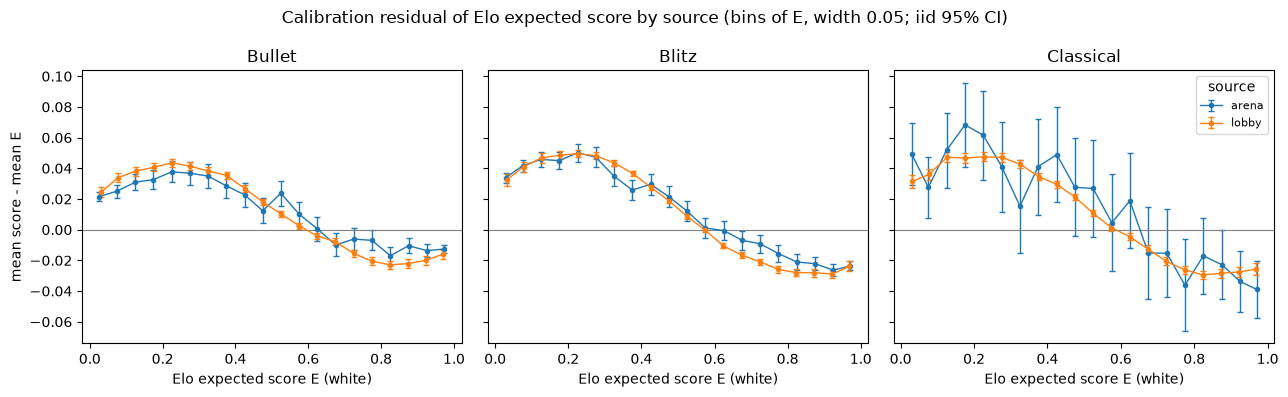

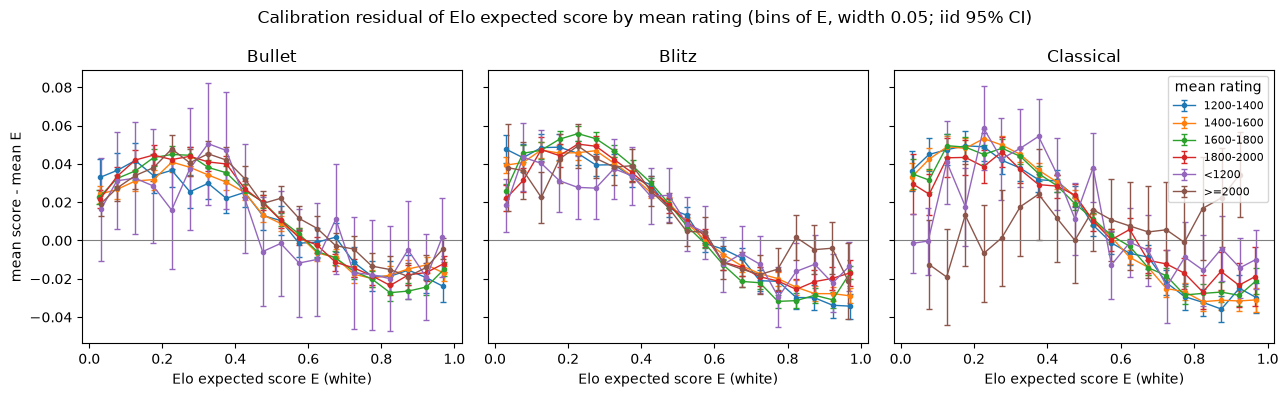

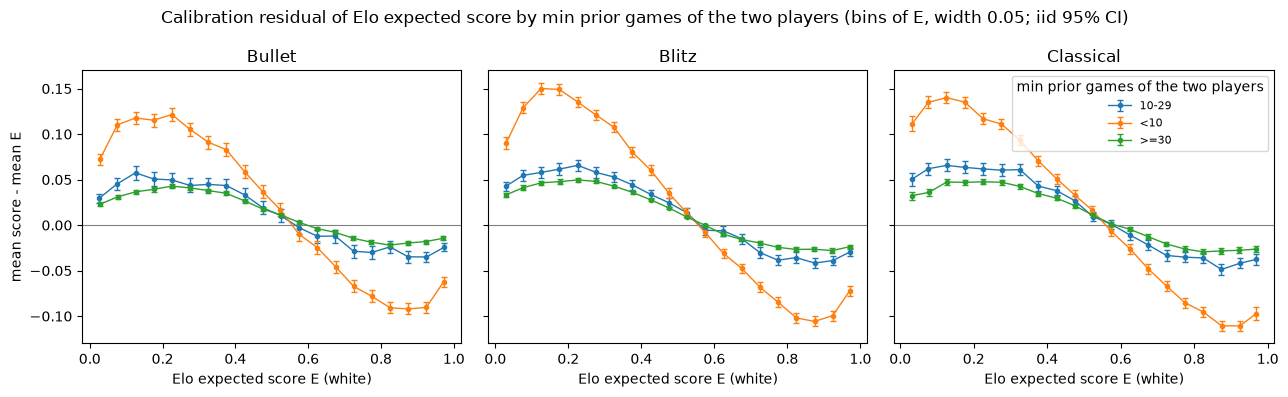

In [17]:
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
for k, fname, title in [("source", "calibration_curve_source.png", "source"), ("band", "calibration_curve_rating.png", "mean rating"), ("experience", "calibration_curve_experience.png", "min prior games of the two players")]:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
    for ax, tc in zip(axes, CLASSES):
        c = curve.filter(pl.col("stratum_type") == k, pl.col("speed") == tc, pl.col("n") >= 200)
        for j, v in enumerate(c["stratum"].unique().sort().to_list()):
            cc = c.filter(pl.col("stratum") == v)
            ax.errorbar(cc["e_mean"], cc["resid_mean"], yerr=1.96 * cc["resid_se"], label=v, color=colors[j], marker="o", ms=3, lw=1, capsize=2)
        ax.axhline(0, color="gray", lw=0.8)
        ax.set_title(tc)
        ax.set_xlabel("Elo expected score E (white)")
    axes[0].set_ylabel("mean score - mean E")
    axes[-1].legend(title=title, fontsize=8)
    fig.suptitle(f"Calibration residual of Elo expected score by {title} (bins of E, width 0.05; iid 95% CI)")
    fig.tight_layout()
    fig.savefig(f"outputs/figures/{fname}", dpi=150)

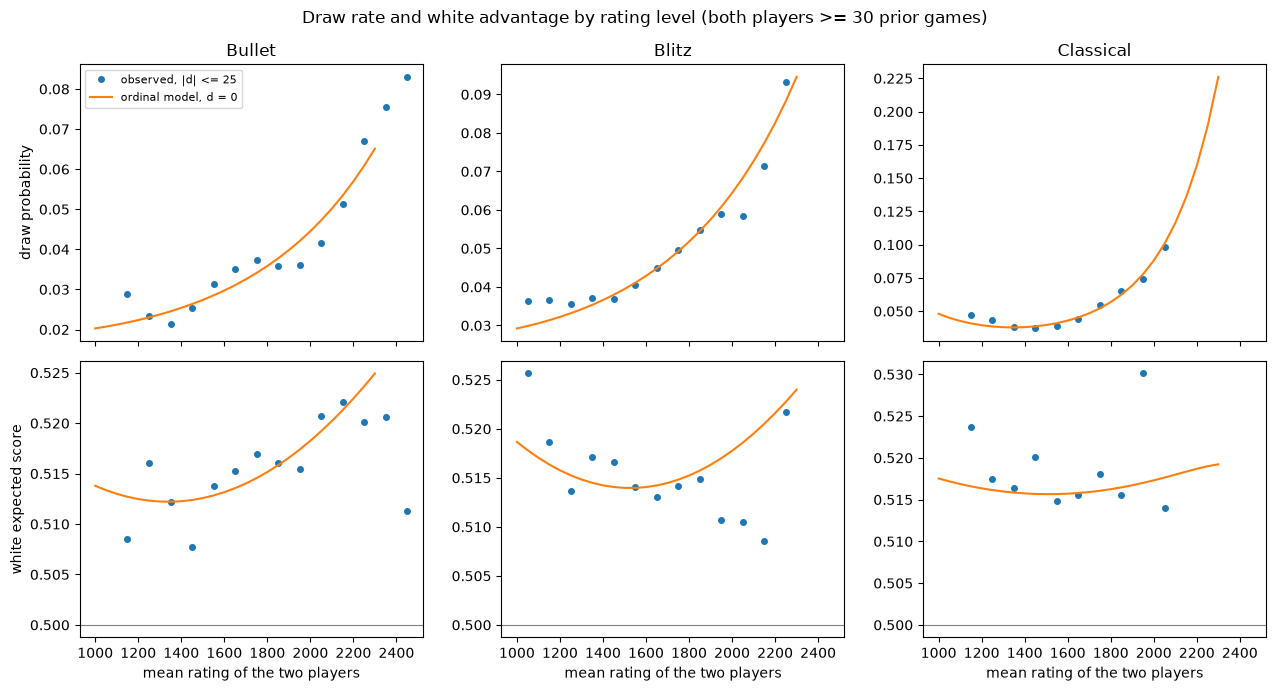

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for j, tc in enumerate(CLASSES):
    lv = level.filter(pl.col("speed") == tc)
    im = implied.filter(pl.col("speed") == tc)
    axes[0, j].plot(lv["r_bin"], lv["draw_rate"], "o", ms=4, label="observed, |d| <= 25")
    axes[0, j].plot(im["rbar"], im["p_draw_d0"], "-", label="ordinal model, d = 0")
    axes[1, j].plot(lv["r_bin"], lv["white_score"], "o", ms=4, label="observed, |d| <= 25")
    axes[1, j].plot(im["rbar"], im["white_score_d0"], "-", label="ordinal model, d = 0")
    axes[1, j].axhline(0.5, color="gray", lw=0.8)
    axes[0, j].set_title(tc)
    axes[1, j].set_xlabel("mean rating of the two players")
axes[0, 0].set_ylabel("draw probability")
axes[1, 0].set_ylabel("white expected score")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Draw rate and white advantage by rating level (both players >= {N_EST} prior games)")
fig.tight_layout()
fig.savefig("outputs/figures/calibration_level.png", dpi=150)

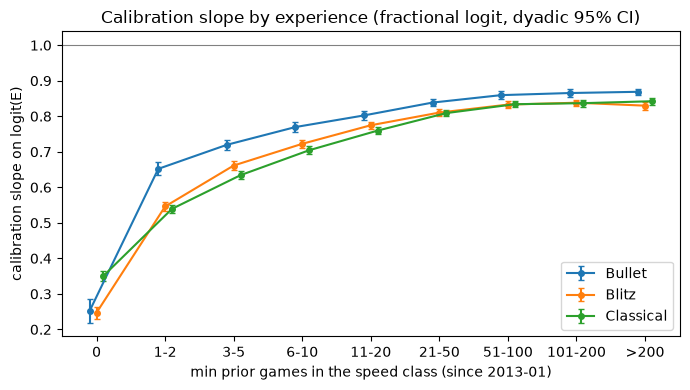

In [19]:
order_exp = ["0", "1-2", "3-5", "6-10", "11-20", "21-50", "51-100", "101-200", ">200"]
fig, ax = plt.subplots(figsize=(7, 4))
for j, tc in enumerate(CLASSES):
    c = cox.filter(pl.col("speed") == tc, pl.col("stratum_type") == "experience").with_columns(o=pl.col("stratum").replace_strict({v: i for i, v in enumerate(order_exp)}, return_dtype=pl.Int32)).sort("o")
    ax.errorbar(c["o"] + (j - 1) * 0.1, c["slope"], yerr=1.96 * c["slope_se"], marker="o", ms=4, capsize=2, label=tc, color=colors[j])
ax.axhline(1, color="gray", lw=0.8)
ax.set_xticks(range(len(order_exp)), order_exp)
ax.set_xlabel("min prior games in the speed class (since 2013-01)")
ax.set_ylabel("calibration slope on logit(E)")
ax.set_title("Calibration slope by experience (fractional logit, dyadic 95% CI)")
ax.legend()
fig.tight_layout()
fig.savefig("outputs/figures/calibration_experience.png", dpi=150)